# 03 - Logística

**Pergunta central:** qual é a experiência de entrega (tempo, atraso, frete), e como atraso impacta a satisfação?

## 1. Configuração

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

from utils import br, limpa, COR, COR_DESTAQUE, COR_CINZA, JANELA_INICIO as RECORTE_INICIO, JANELA_FIM as RECORTE_FIM

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

PROCESSED = Path("../data/processed")
FIG = Path("../reports/figures")
TAB = Path("../reports/tabelas")
for pasta in (FIG, TAB):
    pasta.mkdir(parents=True, exist_ok=True)


## 2. Carga e recorte

Analisar com que frequência os clientes compram novamente e se o histórico de entregas com atraso afeta o comportamento de recompra.

In [2]:
colunas_data = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
base = pd.read_csv(PROCESSED / "base_pedidos_entregues.csv", parse_dates=colunas_data)
base["mes_compra"] = base["order_purchase_timestamp"].dt.to_period("M")

df = base[
    (base["mes_compra"] >= RECORTE_INICIO) & (base["mes_compra"] <= RECORTE_FIM)
].copy()

print(f"Pedidos entregues no período: {br(len(df))}")
print(f"Com nota de avaliação: {br(df['review_score'].notna().sum())} ({df['review_score'].notna().mean():.0%})")

Pedidos entregues no período: 94.834
Com nota de avaliação: 94.198 (99%)


## 3. Lead time: quanto leva cada etapa da entrega?

Calcula o tempo de cada etapa (aprovação, postagem e transporte) e o lead time total.

In [3]:
# Já calculadas no notebook 01, mas aqui checamos
print("Lead time (dias) - estatísticas:\n")
for col in ["dias_aprovacao", "dias_postagem", "dias_transporte", "lead_time_total"]:
    print(f"{col:25s}: {df[col].describe()[['count','mean','std','min','max']]}")

Lead time (dias) - estatísticas:

dias_aprovacao           : count   94,820.00
mean         0.40
std          0.80
min          0.00
max         30.89
Name: dias_aprovacao, dtype: float64
dias_postagem            : count   94,819.00
mean         2.82
std          3.40
min          0.00
max        125.76
Name: dias_postagem, dtype: float64
dias_transporte          : count   94,833.00
mean         9.37
std          8.77
min          0.00
max        205.19
Name: dias_transporte, dtype: float64
lead_time_total          : count   94,834.00
mean        12.60
std          9.56
min          0.53
max        209.63
Name: lead_time_total, dtype: float64



Resume das etapas:
                 n_pedidos  dias_medio
dias_aprovacao   94,820.00        0.40
dias_postagem    94,819.00        2.82
dias_transporte  94,833.00        9.37


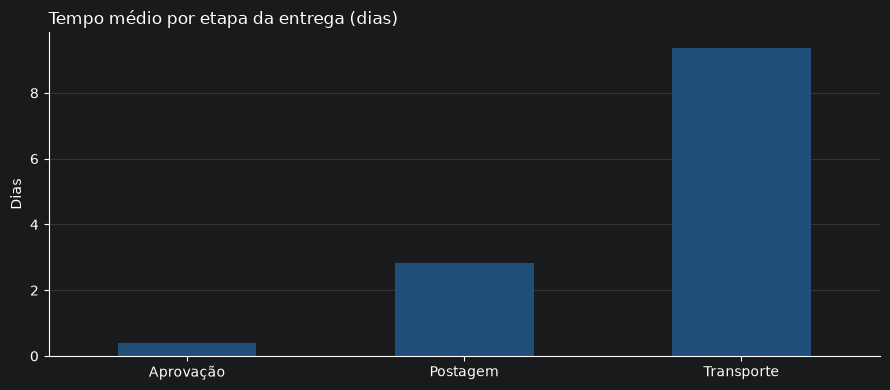

In [4]:
etapas = df[["dias_aprovacao", "dias_postagem", "dias_transporte"]].describe().loc[["count", "mean"]].T
etapas.columns = ["n_pedidos", "dias_medio"]

print("\nResume das etapas:")
print(etapas)

fig, ax = plt.subplots(figsize=(9, 4))
etapas["dias_medio"].plot(kind="bar", ax=ax, color=COR)
ax.set_title("Tempo médio por etapa da entrega (dias)", loc="left", fontsize=12)
ax.set_ylabel("Dias")
ax.set_xlabel(None)
ax.set_xticklabels(["Aprovação", "Postagem", "Transporte"], rotation=0)
limpa(ax)
plt.tight_layout()
plt.savefig(FIG / "05_etapas_entrega.png", dpi=150)
plt.show()

## 4. Atraso: quantos pedidos chegaram atrasados?

Estimar quanto dinheiro a operação perde em receita potencial futura devido aos pedidos que chegam atrasados e frustram os consumidores.

In [5]:
ORDEM_ATRASO = [
    "Muito cedo (>5d antes)",
    "No prazo ou cedo (até 5d)",
    "Atraso leve (1 a 5d)",
    "Atraso moderado (5 a 10d)",
    "Atraso grave (>10d)",
]

df_nota = df[df["review_score"].notna()].copy()

print(f"Entregues no período:                {br(len(df))}")
print(f"Com nota de avaliação (base usada):  {br(len(df_nota))}")

df_nota["dias_atraso_cat"] = pd.cut(
    df_nota["dias_atraso"],
    bins=[-np.inf, -5, 0, 5, 10, np.inf],
    labels=ORDEM_ATRASO,
)

atraso_dist = df_nota["dias_atraso_cat"].value_counts().reindex(ORDEM_ATRASO)
n_atrasados = int(atraso_dist[ORDEM_ATRASO[2:]].sum())

# Checagem: as faixas de atraso têm de bater com a flag "atrasado" (dias_atraso > 0)
assert n_atrasados == int((df_nota["dias_atraso"] > 0).sum()), "Faixas e flag de atraso divergem!"

pct_atrasados = n_atrasados / len(df_nota) * 100
print(f"\nPedidos atrasados: {br(n_atrasados)} ({br(pct_atrasados, 1)}% da base)")
print(f"No prazo ou antes: {br(len(df_nota) - n_atrasados)} ({br(100 - pct_atrasados, 1)}%)")

tabela_faixas = pd.DataFrame({
    "pedidos": atraso_dist,
    "% da base": (atraso_dist / len(df_nota) * 100).round(1),
})
tabela_faixas["% dos atrasados"] = (atraso_dist / n_atrasados * 100).round(1)
tabela_faixas.loc[ORDEM_ATRASO[:2], "% dos atrasados"] = np.nan
print()
print(tabela_faixas)

nota_por_faixa = df_nota.groupby("dias_atraso_cat", observed=True)["review_score"].mean()
print(f"\nNota para 'Atraso leve (1 a 5d)': {nota_por_faixa['Atraso leve (1 a 5d)']:.2f}")
print(f"Nota para 'Atraso grave (>10d)': {nota_por_faixa['Atraso grave (>10d)']:.2f}")

Entregues no período:                94.834
Com nota de avaliação (base usada):  94.198

Pedidos atrasados: 7.625 (8,1% da base)
No prazo ou antes: 86.573 (91,9%)

                           pedidos  % da base  % dos atrasados
dias_atraso_cat                                               
Muito cedo (>5d antes)       77828      82.60              NaN
No prazo ou cedo (até 5d)     8745       9.30              NaN
Atraso leve (1 a 5d)          3547       3.80            46.50
Atraso moderado (5 a 10d)     1853       2.00            24.30
Atraso grave (>10d)           2225       2.40            29.20

Nota para 'Atraso leve (1 a 5d)': 3.46
Nota para 'Atraso grave (>10d)': 1.70


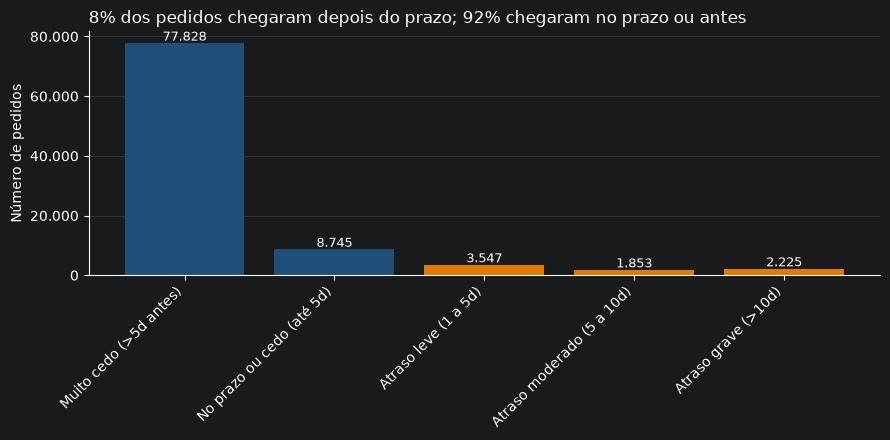

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))

cores = [COR_DESTAQUE if faixa.startswith("Atraso") else COR for faixa in atraso_dist.index]
ax.bar(range(len(atraso_dist)), atraso_dist.values, color=cores)

for i, v in enumerate(atraso_dist.values):
    ax.text(i, v + atraso_dist.max() * 0.01, br(v), ha="center", fontsize=9)

ax.set_xticks(range(len(atraso_dist)))
ax.set_xticklabels(atraso_dist.index, rotation=45, ha="right")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v)))
ax.set_ylabel("Número de pedidos")
ax.set_title(
    f"{br(pct_atrasados, 0)}% dos pedidos chegaram depois do prazo; "
    f"{br(100 - pct_atrasados, 0)}% chegaram no prazo ou antes",
    loc="left", fontsize=12,
)
limpa(ax)
plt.tight_layout()
plt.savefig(FIG / "06_distribuicao_atrasos.png", dpi=150)
plt.show()

## 5. A relação crítica: atraso × satisfação

In [7]:
# Análise por categoria de atraso (base única: entregues com nota)
atraso_nota = (
    df_nota.groupby("dias_atraso_cat", observed=True)["review_score"]
    .agg(["count", "mean", "std"])
    .reindex(ORDEM_ATRASO)
    .round(2)
)
print(atraso_nota)

print(f"\nNota média geral: {df_nota['review_score'].mean():.2f}")

                           count  mean  std
dias_atraso_cat                            
Muito cedo (>5d antes)     77828  4.31 1.14
No prazo ou cedo (até 5d)   8745  4.15 1.21
Atraso leve (1 a 5d)        3547  3.46 1.57
Atraso moderado (5 a 10d)   1853  1.89 1.39
Atraso grave (>10d)         2225  1.70 1.23

Nota média geral: 4.15


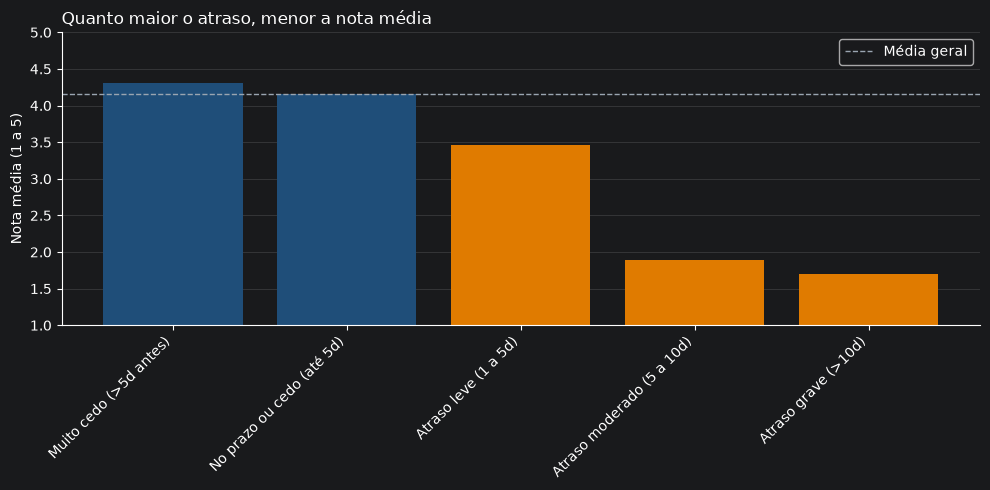


Nota média geral: 4.15
Nota para 'Muito cedo (>5d antes)': 4.31
Nota para 'No prazo ou cedo (até 5d)': 4.15
Nota para 'Atraso leve (1 a 5d)': 3.46
Nota para 'Atraso moderado (5 a 10d)': 1.89
Nota para 'Atraso grave (>10d)': 1.70


In [8]:
ORDEM_ATRASO = [
    "Muito cedo (>5d antes)",
    "No prazo ou cedo (até 5d)",
    "Atraso leve (1 a 5d)",
    "Atraso moderado (5 a 10d)",
    "Atraso grave (>10d)",
]

fig, ax = plt.subplots(figsize=(10, 5))

dados_plot = (
    df_nota.groupby("dias_atraso_cat", observed=True)["review_score"]
    .mean()
    .reindex(ORDEM_ATRASO)
)

cores_plot = [COR_DESTAQUE if cat.startswith("Atraso") else COR for cat in dados_plot.index]

ax.bar(range(len(dados_plot)), dados_plot.values, color=cores_plot)
ax.set_xticks(range(len(dados_plot)))
ax.set_xticklabels(dados_plot.index, rotation=45, ha="right")
ax.set_ylabel("Nota média (1 a 5)")
ax.set_ylim(1, 5)
ax.axhline(y=df_nota["review_score"].mean(), color=COR_CINZA, linestyle="--", linewidth=1, label="Média geral")
ax.set_title("Quanto maior o atraso, menor a nota média", loc="left", fontsize=12)
ax.legend()
limpa(ax)
plt.tight_layout()
plt.savefig(FIG / "07_atraso_vs_nota.png", dpi=150)
plt.show()

print(f"\nNota média geral: {df_nota['review_score'].mean():.2f}")
for cat in ORDEM_ATRASO:
    print(f"Nota para '{cat}': {dados_plot[cat]:.2f}")

## 6. Atraso por estado (onde é pior?)

In [9]:
atraso_uf = df_nota.groupby("customer_state").agg(
    pedidos=("order_id", "count"),
    atrasados=("atrasado", "sum"),
    atrasado_pct=("atrasado", "mean"),
    dias_atraso_medio=("dias_atraso", "mean"),
    nota_media=("review_score", "mean"),
).sort_values("atrasado_pct", ascending=False)
atraso_uf["atrasado_pct"] *= 100
atraso_uf["atrasados"] = atraso_uf["atrasados"].astype(int)

print(atraso_uf.round(2).head(15))

assert atraso_uf["atrasados"].sum() == n_atrasados, "Total por estado não bate com o total geral!"
print(f"\nTotal de atrasados (todos os estados): {br(atraso_uf['atrasados'].sum())}")

rj = atraso_uf.loc["RJ", "atrasados"]
print(f"RJ: {br(rj)} atrasados ({rj / n_atrasados:.1%} do total)")

quatro = ["AL", "MA", "PI", "CE"]
soma_quatro = atraso_uf.loc[quatro, "atrasados"].sum()
print(f"AL+MA+PI+CE: {br(soma_quatro)} atrasados ({soma_quatro / n_atrasados:.1%} do total)")

                pedidos  atrasados  atrasado_pct  dias_atraso_medio  \
customer_state                                                        
AL                  389         90         23.14              -8.29   
MA                  697        137         19.66              -8.77   
PI                  463         75         16.20             -10.43   
CE                 1248        194         15.54              -9.89   
SE                  329         50         15.20              -9.16   
BA                 3180        438         13.77             -10.13   
RJ                12036       1619         13.45             -10.94   
TO                  269         35         13.01             -11.38   
RR                   39          5         12.82             -15.44   
ES                 1939        232         11.96              -9.90   
PA                  919        109         11.86             -13.39   
MS                  694         81         11.67             -10.31   
PE    

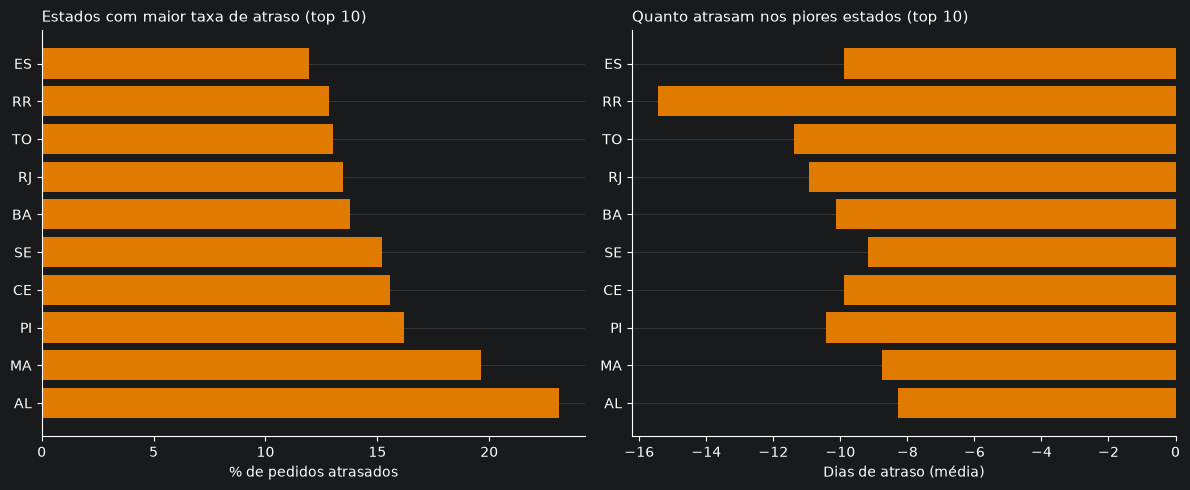

In [10]:
top_atraso = atraso_uf.head(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: % atrasado por estado
axes[0].barh(top_atraso.index, top_atraso["atrasado_pct"], color=COR_DESTAQUE)
axes[0].set_xlabel("% de pedidos atrasados")
axes[0].set_title("Estados com maior taxa de atraso (top 10)", loc="left", fontsize=11)

# Gráfico 2: dias de atraso médio por estado
axes[1].barh(top_atraso.index, top_atraso["dias_atraso_medio"], color=COR_DESTAQUE)
axes[1].set_xlabel("Dias de atraso (média)")
axes[1].set_title("Quanto atrasam nos piores estados (top 10)", loc="left", fontsize=11)

for ax in axes:
    limpa(ax)

plt.tight_layout()
plt.savefig(FIG / "08_atraso_por_estado.png", dpi=150)
plt.show()

## 7. Frete por estado (quanto custa entregar longe?)

In [11]:
frete_uf = df_nota.groupby("customer_state").agg(
    pedidos=("order_id", "count"),
    frete_medio=("frete", "mean"),
    frete_pct_gmv=("frete", lambda x: (x.sum() / df.loc[x.index, "receita_produtos"].sum() * 100)),
).sort_values("frete_pct_gmv", ascending=False)

print("Frete por estado (top 10):")
frete_uf.round(2).head(10)

Frete por estado (top 10):


,pedidos,frete_medio,frete_pct_gmv
customer_state,,,
RR,39,47.86,27.99
MA,697,42.94,26.09
RO,241,46.61,24.69
AM,143,37.62,24.44
SE,329,40.47,24.42
PI,463,43.06,24.07
TO,269,42.32,23.77
AC,77,45.66,22.65
PE,1553,35.86,22.54


## 8. A hipótese central: atraso → nota baixa → recompra afetada

Teste de correlação e impacto quantitativo.

In [12]:
# Correlação entre dias de atraso e nota
corr = df_nota["dias_atraso"].corr(df_nota["review_score"])
print(f"Correlação (dias_atraso, review_score): {corr:.3f}")
print(f"Interpretação: quanto mais atrasado, mais negativa a nota (correlação negativa)")

# Segmentação: qual % de clientes satisfeitos em cada grupo?
df_nota["satisfeito"] = df_nota["review_score"] >= 4
satisfacao_atraso = df_nota.groupby("dias_atraso_cat")["satisfeito"].agg(["sum", "count", "mean"]).round(3)
satisfacao_atraso.columns = ["satisfeitos", "total", "taxa_satisfacao"]

print(f"\nTaxa de clientes satisfeitos (nota >= 4) por categoria de atraso:")
print(satisfacao_atraso)

Correlação (dias_atraso, review_score): -0.272
Interpretação: quanto mais atrasado, mais negativa a nota (correlação negativa)

Taxa de clientes satisfeitos (nota >= 4) por categoria de atraso:
                           satisfeitos  total  taxa_satisfacao
dias_atraso_cat                                               
Muito cedo (>5d antes)           64847  77828             0.83
No prazo ou cedo (até 5d)         6817   8745             0.78
Atraso leve (1 a 5d)              2054   3547             0.58
Atraso moderado (5 a 10d)          315   1853             0.17
Atraso grave (>10d)                262   2225             0.12


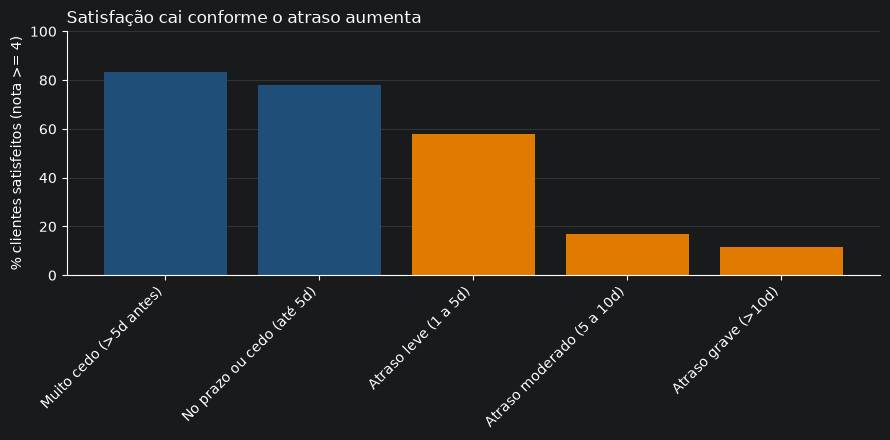

In [13]:
# Visualização: satisfação por atraso
fig, ax = plt.subplots(figsize=(9, 4.5))
satisfacao_plot = df_nota.groupby("dias_atraso_cat")["satisfeito"].mean() * 100
cores_sat = [COR_DESTAQUE if str(cat).startswith("Atraso") else COR for cat in satisfacao_plot.index]

ax.bar(range(len(satisfacao_plot)), satisfacao_plot.values, color=cores_sat)
ax.set_xticks(range(len(satisfacao_plot)))
ax.set_xticklabels(satisfacao_plot.index, rotation=45, ha="right")
ax.set_ylabel("% clientes satisfeitos (nota >= 4)")
ax.set_ylim(0, 100)
ax.set_title("Satisfação cai conforme o atraso aumenta", loc="left", fontsize=12)
limpa(ax)
plt.tight_layout()
plt.savefig(FIG / "09_satisfacao_por_atraso.png", dpi=150)
plt.show()

## 9. Salvar tabelas de suporte

In [14]:
# Resumo da base, para reproduzir os números do relatório
resumo_base = pd.Series({
    "entregues_periodo": len(df_nota),
    "com_nota": len(df_nota),
    "atrasados": n_atrasados,
    "pct_atrasados": round(pct_atrasados, 2),
})
resumo_base.rename("valor").to_csv(TAB / "base_atrasos_resumo.csv")

atraso_dist.rename("pedidos").to_csv(TAB / "distribuicao_atrasos.csv")
atraso_uf.to_csv(TAB / "atraso_por_estado.csv")
frete_uf.to_csv(TAB / "frete_por_estado.csv")
atraso_nota.to_csv(TAB / "atraso_vs_nota.csv")

print("Tabelas salvas em", TAB.resolve())

Tabelas salvas em D:\first-tech-challenge-fiap\reports\tabelas
